# The initial growth rate does not predict whether the oscillation survives

The growth-rate formula, $\lambda = -b/2m + (g/2)\,k_{cv}/(k_{cv}+k_{pass})$ with the valve gain $g(\bar P, \delta)$, gives the rate at which the oscillation grows or decays *at the current state of the resonator*. Evaluated at the start of a run — mean pressure $P_0$, temperature $T_{in}$, the amplitude of the kick $\delta_0$ — it gives the initial growth rate $\lambda_{init}$. It is tempting to read $\lambda_{init} > 0$ as "the oscillation will build up" and $\lambda_{init} < 0$ as "it will die". This notebook shows, with the full simulation as the judge, that this reading is wrong.

The reason is simple. While the oscillation grows, the mean pressure of the resonator drifts (it fills toward $P_{in}$), and that drift moves the working points of the two reed valves. Past a certain mean pressure the valves stop driving and start damping, and $\lambda$ turns negative. So $\lambda$ is not a constant of the run: it starts at $\lambda_{init}$ and falls as the resonator fills. A run whose oscillation has grown large enough by then holds the mean pressure in place and settles into a steady oscillation; a run whose oscillation is still small when the drive is lost collapses — a stall — even though it started with $\lambda_{init} > 0$.

Three figures: **(1)** $\lambda_{init}$ against the outcome for the 37 runs of the parameter sweeps and for 60 settings with all parameters drawn at random — the two outcomes overlap over most of the range of $\lambda_{init}$; **(2)** pairs of runs with the same $\lambda_{init}$ and opposite fates; **(3)** for one such pair, $\lambda$ and the mean pressure along the run: both start at the same rate, one settles to zero, the other is dragged negative by the filling resonator.

$\lambda_{init}$ is computed from the formula at the initial state; `lambda_growth_rate_check.ipynb` verified that this matches the growth rate measured on the simulated envelope to a few percent. Runtime: about 4 minutes.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4)


class Model:
    """Full model (reed valves, gas piston, sealed passive volume) and the growth-rate formula."""

    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo]); out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def run(self, t_max=6.0, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Run until the outcome is settled: 'steady' when the half swing has been flat to 1 percent for 0.5 s (and exceeds
        10 mbar), 'stall' when it has fallen below a tenth of its maximum or the piston has stopped.  Returns the outcome
        and the per-cycle trace (time, mean pressure, mean temperature, mean piston position, half swing)."""
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        y = [self.x0, self.v0, M0, self.cv * M0 * self.T0]
        ts, Ps, Ts, xs = [], [], [], []; t0 = 0.0; verdict = None
        while t0 < t_max - 1e-9:
            t1 = min(t0 + chunk, t_max)
            te = np.append(np.arange(t0, t1, 1.0 / fs), t1)
            sol = solve_ivp(self.full_ode, (t0, t1), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            x, v, M, E = sol.y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
            ts.append(sol.t[:-1]); Ps.append(P[:-1]); Ts.append(T[:-1]); xs.append(x[:-1]); y = sol.y[:, -1]; t0 = t1
            if np.abs(v[sol.t > t1 - 0.05]).max() < 1e-3 and t1 > 0.3:
                verdict = 'stall'; break
            if t1 >= 1.0:
                tr = per_cycle(np.concatenate(ts), np.concatenate(Ps), np.concatenate(Ts), np.concatenate(xs))
                tm, half = tr[0], tr[4]
                if len(tm) > 20:
                    h = half[tm > t1 - 0.5]
                    if h.mean() > 1e3 and (h.max() - h.min()) < 0.01 * h.mean():
                        verdict = 'steady'; break
                    if half.max() > 500.0 and half[tm > t1 - 0.3].max() < 0.1 * half.max():
                        verdict = 'stall'; break
        tr = per_cycle(np.concatenate(ts), np.concatenate(Ps), np.concatenate(Ts), np.concatenate(xs))
        if verdict is None:
            verdict = 'steady' if tr[4][tr[0] > t_max - 0.2].mean() > 1e3 else 'stall'
        return verdict, tr

    # ---- the growth-rate formula ----
    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def lam(self, Pb, Tb, xb, delta):
        """lambda = -b/2m + (g/2) kcv/(kcv+kpass) with the finite-amplitude valve gains, at the slow state (Pbar, Tbar, xbar, delta)."""
        Vc = self.V0_cv + self.A_neck * xb; Vp = self.V0_pass - self.A_neck * xb
        Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pp * self.A_neck ** 2 / Vp
        if delta > 1.0:
            vi = self.reed_vec(self.P_in - Pb + delta * self.CPS); vo = self.reed_vec(Pb - self.P_out + delta * self.CPS)
            Ni, No = 2.0 * (vi * self.CPS).mean() / delta, 2.0 * (vo * self.CPS).mean() / delta
        else:
            h = 1.0
            Ni = (self.reed(self.P_in - Pb + h) - self.reed(self.P_in - Pb - h)) / (2 * h)
            No = (self.reed(Pb - self.P_out + h) - self.reed(Pb - self.P_out - h)) / (2 * h)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Tb * No)
        return -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)

    def delta0(self):
        Vp, Vc, kcv, kp, w0 = self.geom(self.P0)
        return kcv * self.v0 / (w0 * self.A_neck)

    def lam_init(self):
        """The growth rate at the start of the run: mean pressure P0, temperature T_in, amplitude of the kick."""
        return self.lam(self.P0, self.T_in, 0.0, self.delta0())


def per_cycle(t, P, T, x):
    """Cycle edges from upward crossings of P about a peak/trough mean; per-cycle means and half swing."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    if n < 3:
        return [np.array([t[-1]]), np.array([P.mean()]), np.array([T.mean()]), np.array([x.mean()]), np.array([0.5 * (P.max() - P.min())])]
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        rows.append((0.5 * (a + b), P[m].mean(), T[m].mean(), x[m].mean(), 0.5 * (P[m].max() - P[m].min())))
    return [np.array(c) for c in zip(*rows)]


def analyse(model):
    """Outcome of the full run, lambda_init, and lambda along the run (formula at the simulated state, cycle by cycle)."""
    verdict, (tm, Pm, Tm, xm, half) = model.run()
    lam_t = np.array([model.lam(Pm[i], Tm[i], xm[i], half[i]) for i in range(len(tm))])
    return verdict, dict(tm=tm, Pm=Pm, Tm=Tm, xm=xm, half=half, lam=lam_t), model.lam_init()

In [2]:
# ---- the 37 runs of the parameter sweeps (one parameter at a time from the baseline) ----
SWEEPS = {
    'm_max':   ('valve capacity',  [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed factor',     [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping',  [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume',  [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass',     [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick',    [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure',  [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}
rows, traces = [], {}
tic = time.time()
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        model = Model(**{key: v}); verdict, tr, li = analyse(model)
        rows.append(dict(sweep=key, value=v, name='%s = %g' % (key, v), lam_init=li, outcome=verdict)); traces[(key, v)] = tr
        print('%-8s = %-8g  lambda_init %6.2f 1/s   outcome %-6s   [%3.0f s]' % (key, v, li, verdict, time.time() - tic))
df = pd.DataFrame(rows)

# ---- 60 settings with all seven parameters drawn at random (log-uniform, P_in uniform) ----
BOX = dict(m_max=(3e-4, 3e-3), zeta=(0.45, 1.0), b_gas=(2e-3, 3e-2), V0_pass=(7e-5, 6e-4), m_gas=(7e-4, 4e-3), v0=(1.0, 12.0))
rng = np.random.default_rng(7); rowsR = []
for i in range(60):
    kw = {k: float(np.exp(rng.uniform(np.log(lo), np.log(hi)))) for k, (lo, hi) in BOX.items()}
    kw['P_in'] = float(rng.uniform(5.9e5, 6.3e5))
    model = Model(**kw); verdict, tr, li = analyse(model)
    rowsR.append(dict(case=i, **kw, lam_init=li, outcome=verdict))
print('random settings done  [%3.0f s]' % (time.time() - tic))
dfR = pd.DataFrame(rowsR)

for name, d in [('parameter sweeps', df), ('random settings', dfR)]:
    st = d[d.outcome == 'stall']; ok = d[d.outcome == 'steady']
    print('%s: %d runs, %d steady and %d stall.  Stall runs with lambda_init > 0: %d of %d.  Steady runs with lambda_init < 0: %d of %d.  '
          'lambda_init ranges: steady %.1f to %.1f 1/s, stall %.1f to %.1f 1/s.  "lambda_init > 0" right in %d of %d.'
          % (name, len(d), len(ok), len(st), (st.lam_init > 0).sum(), len(st), (ok.lam_init < 0).sum(), len(ok),
             ok.lam_init.min(), ok.lam_init.max(), st.lam_init.min(), st.lam_init.max(), ((d.lam_init > 0) == (d.outcome == 'steady')).sum(), len(d)))

m_max    = 0.00025   lambda_init   0.46 1/s   outcome stall    [  3 s]


m_max    = 0.0005    lambda_init   2.59 1/s   outcome steady   [  6 s]


m_max    = 0.001     lambda_init   6.85 1/s   outcome steady   [  8 s]


m_max    = 0.002     lambda_init  15.37 1/s   outcome steady   [ 10 s]


m_max    = 0.004     lambda_init  32.40 1/s   outcome steady   [ 12 s]


...

P_in     = 590000    lambda_init   4.64 1/s   outcome stall    [ 62 s]


P_in     = 600000    lambda_init   6.85 1/s   outcome steady   [ 64 s]


P_in     = 620000    lambda_init   4.57 1/s   outcome stall    [ 66 s]


P_in     = 650000    lambda_init   2.12 1/s   outcome stall    [ 67 s]


random settings done  [197 s]
parameter sweeps: 37 runs, 23 steady and 14 stall.  Stall runs with lambda_init > 0: 11 of 14.  Steady runs with lambda_init < 0: 1 of 23.  lambda_init ranges: steady -9.1 to 32.4 1/s, stall -4.8 to 7.3 1/s.  "lambda_init > 0" right in 25 of 37.
random settings: 60 runs, 21 steady and 39 stall.  Stall runs with lambda_init > 0: 26 of 39.  Steady runs with lambda_init < 0: 6 of 21.  lambda_init ranges: steady -13.4 to 26.4 1/s, stall -8.2 to 28.0 1/s.  "lambda_init > 0" right in 28 of 60.


## Figure 1. $\lambda_{init}$ against the outcome

Each marker is one run; blue filled = steady oscillation, orange open = stall, as decided by the full simulation. If $\lambda_{init}$ decided the outcome, all the orange markers would lie left of the dashed line and all the blue ones right of it.

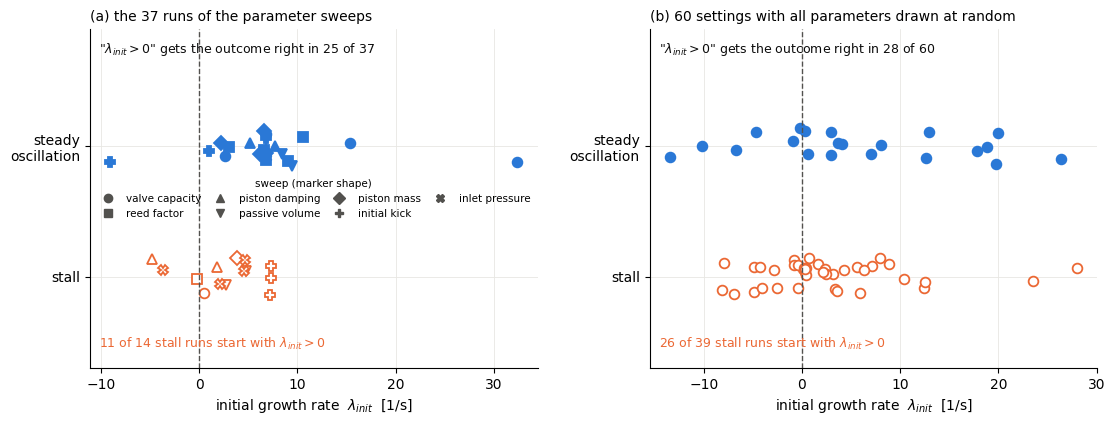

In [3]:
ccol = {'steady': BLUE, 'stall': ORANGE}
marks = dict(zip(SWEEPS, ['o', 's', '^', 'v', 'D', 'P', 'X']))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4)); fig.subplots_adjust(wspace=0.25)
rng2 = np.random.default_rng(3)
for ax, d, title in [(axs[0], df, '(a) the 37 runs of the parameter sweeps'), (axs[1], dfR, '(b) 60 settings with all parameters drawn at random')]:
    for r in d.itertuples():
        y = (1.0 if r.outcome == 'steady' else 0.0) + rng2.uniform(-0.15, 0.15)
        mk = marks[r.sweep] if 'sweep' in d.columns else 'o'
        ax.plot(r.lam_init, y, mk, color=ccol[r.outcome], ms=7, mew=1.3, mfc=ccol[r.outcome] if r.outcome == 'steady' else 'white')
    ax.axvline(0, color=INK2, lw=1, ls='--')
    ax.set_yticks([0, 1]); ax.set_yticklabels(['stall', 'steady\noscillation']); ax.set_ylim(-0.7, 1.9)
    ax.set_xlabel(r'initial growth rate  $\lambda_{init}$  [1/s]'); ax.set_title(title, fontsize=10, loc='left')
    st = d[d.outcome == 'stall']; ok = d[d.outcome == 'steady']
    ax.text(0.02, 0.06, r'%d of %d stall runs start with $\lambda_{init} > 0$' % ((st.lam_init > 0).sum(), len(st)), transform=ax.transAxes, fontsize=9, color=ORANGE)
    ax.text(0.02, 0.93, r'"$\lambda_{init} > 0$" gets the outcome right in %d of %d' % (((d.lam_init > 0) == (d.outcome == 'steady')).sum(), len(d)), transform=ax.transAxes, fontsize=9, color=INK)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
from matplotlib.lines import Line2D
axs[0].legend(handles=[Line2D([], [], marker=marks[k], color=INK2, ls='', ms=6, label=SWEEPS[k][0]) for k in SWEEPS],
              frameon=False, fontsize=7.5, loc='center', ncol=4, title='sweep (marker shape)', title_fontsize=7.5, columnspacing=0.8)
plt.show()

## Figure 2. Same $\lambda_{init}$, opposite fate

For each stall run of the sweeps, the steady run with the closest $\lambda_{init}$ is paired with it; the three closest pairs are shown. On a logarithmic amplitude axis the envelopes leave the start parallel — the same relative growth rate is exactly what $\lambda_{init}$ fixes — and then part ways: one settles at the steady amplitude, the other collapses.

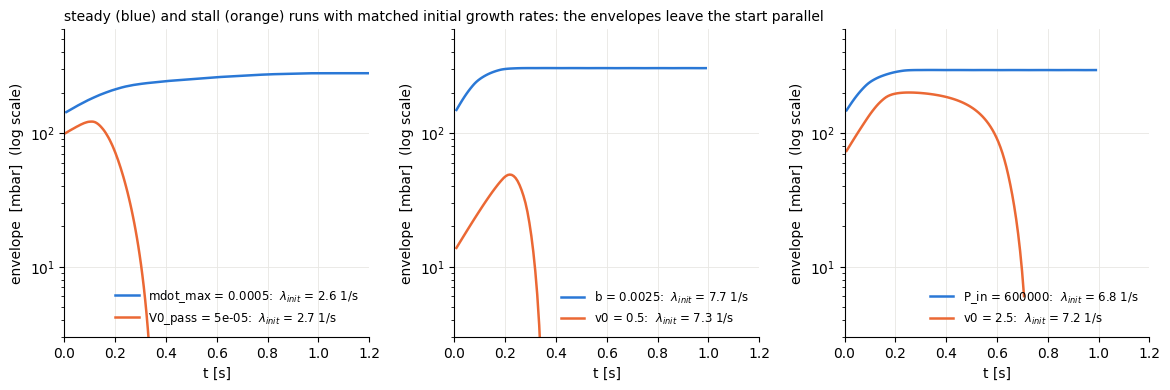

pairs shown (stall run, steady run, lambda_init of each):
   V0_pass = 5e-05   stall     2.70 1/s      m_max = 0.0005    steady    2.59 1/s
   v0 = 0.5          stall     7.35 1/s      b_gas = 0.0025    steady    7.68 1/s
   v0 = 2.5          stall     7.23 1/s      P_in = 600000     steady    6.85 1/s


In [4]:
st = df[df.outcome == 'stall']; ok = df[df.outcome == 'steady']
cands = []
for r in st.itertuples():
    if r.lam_init <= 0:
        continue
    for q in ok.itertuples():
        cands.append((abs(q.lam_init - r.lam_init) / max(abs(r.lam_init), 0.1), r.name, q.name, r.lam_init, q.lam_init, (r.sweep, r.value), (q.sweep, q.value)))
cands.sort(); pairs, used = [], set()
for c in cands:                                   # closest pairs first, each run used once
    if c[1] in used or c[2] in used:
        continue
    pairs.append(c); used.update([c[1], c[2]])
fig, axs = plt.subplots(1, 3, figsize=(14, 4.0)); fig.subplots_adjust(wspace=0.28)
for ax, (rel, n_st, n_ok, l_st, l_ok, k_st, k_ok) in zip(axs, pairs[:3]):
    for key, name, li, col in [(k_ok, n_ok, l_ok, BLUE), (k_st, n_st, l_st, ORANGE)]:
        tr = traces[key]; L = tr['half'] > 0.02 * tr['half'].max()
        ax.plot(tr['tm'][L], tr['half'][L] / 100, '-', color=col, lw=1.8, label='%s:  $\\lambda_{init}$ = %.1f 1/s' % (name.replace('m_max', 'mdot_max').replace('b_gas', 'b').replace('m_gas', 'm'), li))
    ax.set_xlabel('t [s]'); ax.set_ylabel('envelope  [mbar]  (log scale)'); ax.set_xlim(0, 1.2); ax.set_yscale('log'); ax.set_ylim(3, 600)
    ax.legend(frameon=False, fontsize=8.5, loc='lower right')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
axs[0].set_title('steady (blue) and stall (orange) runs with matched initial growth rates: the envelopes leave the start parallel', fontsize=10, loc='left')
plt.show()
print('pairs shown (stall run, steady run, lambda_init of each):')
for rel, n_st, n_ok, l_st, l_ok, *_ in pairs[:3]:
    print('   %-16s  stall   %6.2f 1/s      %-16s  steady  %6.2f 1/s' % (n_st, l_st, n_ok, l_ok))

## Figure 3. Why: $\lambda$ falls as the resonator fills

The closest pair of Figure 2, followed cycle by cycle. Top: the growth rate from the formula evaluated at the simulated state of each cycle. Middle: the envelope. Bottom: the mean pressure. Both runs start at the same $\lambda$. In the steady run the oscillation reaches its full amplitude while the valves still drive; the large swing then holds the mean pressure below $P_0$ and $\lambda$ settles to zero. In the stall run the oscillation is still small when the mean pressure has risen to where the valves stop driving; $\lambda$ goes through zero and then far below it, and the envelope collapses while the resonator fills up to $P_{in}$.

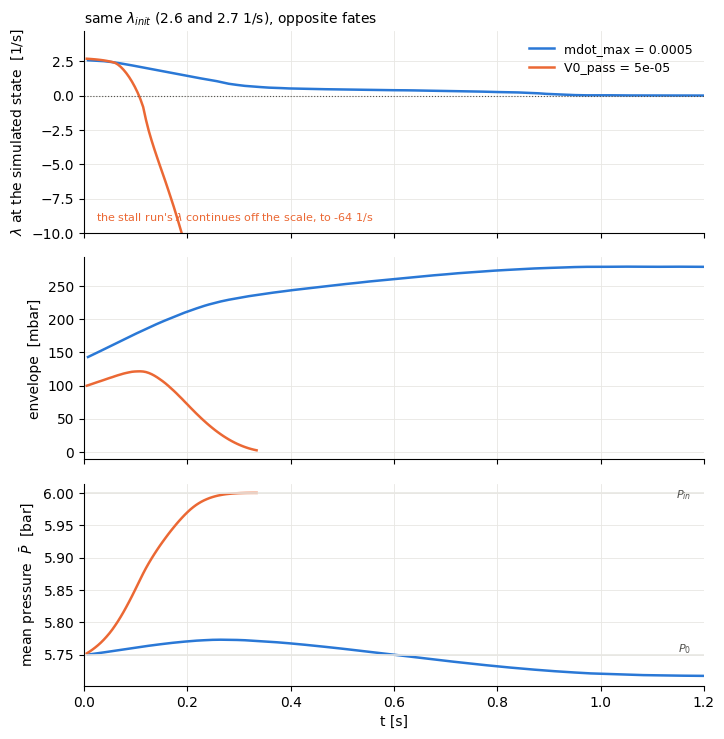

In [5]:
rel, n_st, n_ok, l_st, l_ok, k_st, k_ok = pairs[0]
fig, axs = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True); fig.subplots_adjust(hspace=0.12)
for key, name, li, col in [(k_ok, n_ok, l_ok, BLUE), (k_st, n_st, l_st, ORANGE)]:
    tr = traces[key]; L = tr['half'] > 0.02 * tr['half'].max()
    lab = name.replace('m_max', 'mdot_max').replace('b_gas', 'b').replace('m_gas', 'm')
    axs[0].plot(tr['tm'][L], tr['lam'][L], '-', color=col, lw=1.8, label=lab)
    axs[1].plot(tr['tm'][L], tr['half'][L] / 100, '-', color=col, lw=1.8)
    axs[2].plot(tr['tm'][L], tr['Pm'][L] / 1e5, '-', color=col, lw=1.8)
axs[0].axhline(0, color=INK2, lw=0.8, ls=':'); axs[0].set_ylabel(r'$\lambda$ at the simulated state  [1/s]'); axs[0].legend(frameon=False, fontsize=9)
axs[0].set_ylim(-10, max(traces[k_ok]['lam'].max(), traces[k_st]['lam'].max()) + 2)
axs[0].text(0.02, 0.06, 'the stall run\'s $\\lambda$ continues off the scale, to %.0f 1/s' % traces[k_st]['lam'][traces[k_st]['half'] > 0.02 * traces[k_st]['half'].max()].min(), transform=axs[0].transAxes, fontsize=8, color=ORANGE)
axs[0].set_title(r'same $\lambda_{init}$ (%.1f and %.1f 1/s), opposite fates' % (l_ok, l_st), fontsize=10, loc='left')
axs[1].set_ylabel('envelope  [mbar]')
axs[2].axhline(BASE['P_in'] / 1e5, color=GRID, lw=1.2); axs[2].text(0.98, BASE['P_in'] / 1e5 - 0.008, '$P_{in}$', transform=axs[2].get_yaxis_transform(), ha='right', fontsize=8, color=INK2)
axs[2].axhline(BASE['P0'] / 1e5, color=GRID, lw=1.2); axs[2].text(0.98, BASE['P0'] / 1e5 + 0.004, '$P_0$', transform=axs[2].get_yaxis_transform(), ha='right', fontsize=8, color=INK2)
axs[2].set_ylabel(r'mean pressure  $\bar P$  [bar]'); axs[2].set_xlabel('t [s]'); axs[2].set_xlim(0, 1.2)
for ax in axs:
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
plt.show()

## What to take from this

$\lambda_{init}$ tells you whether the kick grows *at first*. It does not tell you whether the oscillation survives, because $\lambda$ is not a constant of the run: the mean pressure drifts as the resonator fills, the valves' working points move with it, and past a certain mean pressure the valves damp instead of drive. Most stall runs start with $\lambda_{init} > 0$ and die later; runs with identical $\lambda_{init}$ go either way; and $\lambda_{init} \lt 0$ does not mean death either — a kick larger than the steady amplitude starts with $\lambda_{init} \lt 0$ and decays *down* to the steady oscillation (the 20 m/s kick of the sweeps, and 6 of the 21 steady random settings). What decides the outcome is a race between the growth of the oscillation and the filling of the resonator — whether the swing is large enough to hold the mean pressure in place before the drive is lost. That race is what the slow equations (mean mass, mean pressure, amplitude) integrate, and it is why they, and not $\lambda_{init}$, predict the outcome.